# Nghiên Cứu Mạng Tích Chập Sâu (Deep CNNs) Với PyTorch & Keras Trên CIFAR-10

Trong phần trước, thực nghiệm thuần NumPy đã chứng minh: Một tầng tích chập đơn lẻ không thể nắm bắt được cấu trúc ngữ nghĩa phân cấp của ảnh tự nhiên. 

Notebook này triển khai **mạng nơ-ron tích chập sâu phân cấp (Deep Hierarchical CNN)** với 3 khối Conv-BN-ReLU-Pool-Dropout trên toàn bộ 60,000 ảnh CIFAR-10:
1. **Môi trường & Dữ liệu chuẩn mực:** Toàn bộ 40,000 Train, 10,000 Validation và 10,000 Test được nạp và phân tầng đồng bộ cho cả PyTorch và TensorFlow/Keras.
2. **Huấn luyện mô hình PyTorch (Tận dụng GPU Apple Silicon MPS):**
   * Kiến trúc 3 khối tích chập phân cấp tăng dần số kênh: $3 \to 32 \to 64 \to 64$.
   * Tích hợp Batch Normalization và Dropout kiểm soát hiện tượng quá khớp (Overfitting).
   * Theo dõi và vẽ đường cong Train vs. Val loss và accuracy qua 12 epochs.
   * Tách riêng ô đánh giá trên tập Test 10,000 mẫu và vẽ Ma trận nhầm lẫn (Confusion Matrix).
3. **Huấn luyện mô hình TensorFlow / Keras 3 đối ứng:**
   * Cấu hình kiến trúc đối ứng 100% nhằm đảm bảo tính khách quan trong đối sánh.
   * Vẽ đường cong huấn luyện, đánh giá kiểm thử độc lập và vẽ Ma trận nhầm lẫn.
4. **Đối sánh Benchmark 3 chiều:** So sánh toàn diện giữa **Improved Scratch CNN (NumPy)**, **PyTorch CNN** và **Keras CNN** về số tham số, thời gian huấn luyện, độ chính xác và Macro F1.
5. **Khám phá không gian tiềm ẩn (Latent Space) qua PCA 2D:** Trích xuất vector đặc trưng 128 chiều từ mô hình PyTorch để khám phá cấu trúc cụm ngữ nghĩa tự nhiên giữa các lớp đối tượng.


In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

# Lưu ý quan trọng: Import tensorflow trước pandas để tránh xung đột thư viện động OpenMP/pyarrow trên macOS
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11

# Cấu hình thiết bị tăng tốc cho PyTorch
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("PyTorch đang sử dụng: Apple Silicon GPU (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("PyTorch đang sử dụng: NVIDIA CUDA GPU")
else:
    device = torch.device('cpu')
    print("PyTorch đang sử dụng: CPU")

FIGURES_DIR = '../reports/figures'
if not os.path.exists(FIGURES_DIR):
    for p in ['cifar10/reports/figures', 'src/Assigment 04/cifar10/reports/figures']:
        if os.path.exists(p) or os.path.exists(os.path.dirname(p)):
            FIGURES_DIR = p
            break
os.makedirs(FIGURES_DIR, exist_ok=True)

REPORTS_DIR = '../reports'
if not os.path.exists(REPORTS_DIR):
    for p in ['cifar10/reports', 'src/Assigment 04/cifar10/reports']:
        if os.path.exists(p) or os.path.exists(os.path.dirname(p)):
            REPORTS_DIR = p
            break
os.makedirs(REPORTS_DIR, exist_ok=True)


PyTorch đang sử dụng: Apple Silicon GPU (MPS)


In [2]:
DATA_PATH = '../data/cifar10.npz'
if not os.path.exists(DATA_PATH):
    for p in ['cifar10/data/cifar10.npz', 'src/Assigment 04/cifar10/data/cifar10.npz', 'data/cifar10.npz']:
        if os.path.exists(p):
            DATA_PATH = p
            break

data = np.load(DATA_PATH)
X_train_raw = data['X_train']  # (50000, 32, 32, 3)
y_train_raw = data['y_train'].astype(np.int64)
X_test_raw = data['X_test']    # (10000, 32, 32, 3)
y_test = data['y_test'].astype(np.int64)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CLASS_NAMES_VN = ['Máy bay', 'Ô tô', 'Chim', 'Mèo', 'Hươu', 'Chó', 'Ếch', 'Ngựa', 'Tàu thủy', 'Xe tải']

# Phân chia phân tầng: 40,000 Train (80%) và 10,000 Val (20%)
X_train_split, X_val_split, y_train, y_val = train_test_split(
    X_train_raw, y_train_raw, test_size=0.2, stratify=y_train_raw, random_state=RANDOM_SEED
)

# 1. Định dạng Channel-Last cho Keras: (N, 32, 32, 3) chuẩn hóa về [0, 1]
X_train_tf = (X_train_split / 255.0).astype(np.float32)
X_val_tf = (X_val_split / 255.0).astype(np.float32)
X_test_tf = (X_test_raw / 255.0).astype(np.float32)

# 2. Định dạng Channel-First cho PyTorch: (N, 3, 32, 32)
X_train_pt = torch.tensor(X_train_tf.transpose(0, 3, 1, 2), dtype=torch.float32)
y_train_pt = torch.tensor(y_train, dtype=torch.long)

X_val_pt = torch.tensor(X_val_tf.transpose(0, 3, 1, 2), dtype=torch.float32)
y_val_pt = torch.tensor(y_val, dtype=torch.long)

X_test_pt = torch.tensor(X_test_tf.transpose(0, 3, 1, 2), dtype=torch.float32)
y_test_pt = torch.tensor(y_test, dtype=torch.long)

# PyTorch DataLoaders
BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train_pt, y_train_pt), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_pt, y_val_pt), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_pt, y_test_pt), batch_size=BATCH_SIZE, shuffle=False)

print("=== THÔNG TIN DỮ LIỆU HUẤN LUYỆN CIFAR-10 ===")
print(f"Keras Format   -> Train: {X_train_tf.shape}, Val: {X_val_tf.shape}, Test: {X_test_tf.shape}")
print(f"PyTorch Format -> Train: {X_train_pt.shape}, Val: {X_val_pt.shape}, Test: {X_test_pt.shape}")
print(f"Phân phối Train: {np.bincount(y_train)}")
print(f"Phân phối Val:   {np.bincount(y_val)}")
print(f"Phân phối Test:  {np.bincount(y_test)}")


=== THÔNG TIN DỮ LIỆU HUẤN LUYỆN CIFAR-10 ===
Keras Format   -> Train: (40000, 32, 32, 3), Val: (10000, 32, 32, 3), Test: (10000, 32, 32, 3)
PyTorch Format -> Train: torch.Size([40000, 3, 32, 32]), Val: torch.Size([10000, 3, 32, 32]), Test: torch.Size([10000, 3, 32, 32])
Phân phối Train: [4000 4000 4000 4000 4000 4000 4000 4000 4000 4000]
Phân phối Val:   [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
Phân phối Test:  [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## PART 1: Huấn Luyện Mạng CNN Sâu Phân Cấp Bằng PyTorch (Apple Silicon MPS)

Chúng ta xây dựng kiến trúc `CIFAR10Net` gồm 3 khối tích chập sâu và bộ phân loại tuyến tính:
* **Khối 1:** Conv2D(3 $\to$ 32, $3 \times 3$, pad=1) + BatchNorm2D + ReLU + MaxPool2D(2) + Dropout(0.25).
* **Khối 2:** Conv2D(32 $\to$ 64, $3 \times 3$, pad=1) + BatchNorm2D + ReLU + MaxPool2D(2) + Dropout(0.25).
* **Khối 3:** Conv2D(64 $\to$ 64, $3 \times 3$, pad=1) + BatchNorm2D + ReLU + MaxPool2D(2) + Dropout(0.25).
* **Tầng phân loại tiềm ẩn:** Dense(1,024 $\to$ 128) + ReLU + Dropout(0.4) + Dense(128 $\to$ 10).


In [3]:
class CIFAR10Net(nn.Module):
    '''
    Mạng tích chập sâu phân cấp (Hierarchical 3-Block CNN) cho CIFAR-10:
    Bao gồm 3 khối Conv-BN-ReLU-MaxPool-Dropout và bộ phân loại 128 chiều.
    '''
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Khối 1: 32x32 -> 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Khối 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Khối 3: 8x8 -> 4x4
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),
        )
        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.4)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        '''Lan truyền xuôi toàn bộ mạng từ ảnh đầu vào đến logits 10 lớp.'''
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

    def extract_features(self, x):
        '''Trích xuất vector biểu diễn tiềm ẩn 128 chiều phục vụ phân tích không gian ngữ nghĩa.'''
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        return x

model_pt = CIFAR10Net().to(device)
total_params_pt = sum(p.numel() for p in model_pt.parameters() if p.requires_grad)
print(model_pt)
print(f"\nTổng số tham số có thể huấn luyện của PyTorch Model: {total_params_pt:,}")


CIFAR10Net(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.25, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.25, inplace=False)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.25, inplace=False)
  )
  (fc1): Linear(in_features=1024, ou

In [4]:
EPOCHS = 12
criterion_pt = nn.CrossEntropyLoss()
optimizer_pt = optim.Adam(model_pt.parameters(), lr=0.001)

history_pt = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print(f"=== BẮT ĐẦU HUẤN LUYỆN PYTORCH CNN TRÊN {device} ({EPOCHS} EPOCHS) ===")
t_start_pt = time.time()

for epoch in range(1, EPOCHS + 1):
    t_ep_start = time.time()
    
    # Giai đoạn huấn luyện (Train mode)
    model_pt.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_pt.zero_grad()
        outputs = model_pt(inputs)
        loss = criterion_pt(outputs, labels)
        loss.backward()
        optimizer_pt.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels).item()
        total_train += inputs.size(0)
        
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train
    
    # Giai đoạn kiểm định (Validation mode)
    model_pt.eval()
    val_loss, val_correct, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_pt(inputs)
            loss = criterion_pt(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            total_val += inputs.size(0)
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = val_correct / total_val
    
    history_pt['train_loss'].append(epoch_train_loss)
    history_pt['train_acc'].append(epoch_train_acc)
    history_pt['val_loss'].append(epoch_val_loss)
    history_pt['val_acc'].append(epoch_val_acc)
    
    t_ep = time.time() - t_ep_start
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | Thời gian: {t_ep:.1f}s")

t_train_pt = time.time() - t_start_pt
print(f"\n==> Hoàn thành huấn luyện PyTorch CNN trong {t_train_pt:.1f} giây ({t_train_pt/60:.2f} phút)!")


=== BẮT ĐẦU HUẤN LUYỆN PYTORCH CNN TRÊN mps (12 EPOCHS) ===


Epoch 01/12 | Train Loss: 1.7365 - Train Acc: 36.36% | Val Loss: 1.3799 - Val Acc: 49.56% | Thời gian: 8.2s


Epoch 02/12 | Train Loss: 1.4489 - Train Acc: 47.44% | Val Loss: 1.2328 - Val Acc: 55.13% | Thời gian: 5.9s


Epoch 03/12 | Train Loss: 1.3329 - Train Acc: 52.00% | Val Loss: 1.1343 - Val Acc: 59.11% | Thời gian: 6.0s


Epoch 04/12 | Train Loss: 1.2610 - Train Acc: 55.02% | Val Loss: 1.0623 - Val Acc: 61.67% | Thời gian: 6.3s


Epoch 05/12 | Train Loss: 1.2016 - Train Acc: 57.20% | Val Loss: 1.0886 - Val Acc: 61.42% | Thời gian: 5.6s


... (3 outputs left out)

Epoch 09/12 | Train Loss: 1.0504 - Train Acc: 62.80% | Val Loss: 0.9176 - Val Acc: 67.08% | Thời gian: 5.6s


Epoch 10/12 | Train Loss: 1.0374 - Train Acc: 63.67% | Val Loss: 0.9641 - Val Acc: 65.67% | Thời gian: 6.8s


Epoch 11/12 | Train Loss: 1.0175 - Train Acc: 64.26% | Val Loss: 0.9061 - Val Acc: 67.47% | Thời gian: 6.1s


Epoch 12/12 | Train Loss: 0.9977 - Train Acc: 64.88% | Val Loss: 0.8626 - Val Acc: 69.40% | Thời gian: 6.3s

==> Hoàn thành huấn luyện PyTorch CNN trong 73.8 giây (1.23 phút)!


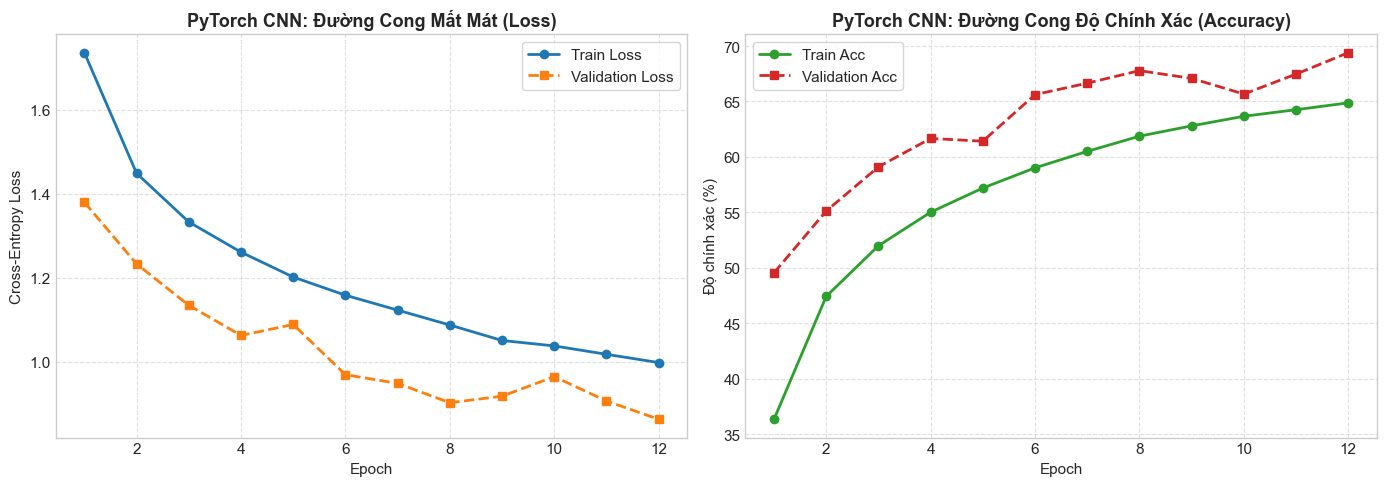

Đã lưu biểu đồ đường cong: ../reports/figures/fig_cifar10_pytorch_curves.png


In [5]:
# Vẽ biểu đồ đường cong mất mát và độ chính xác của PyTorch CNN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, EPOCHS + 1)

# Subplot 1: Train Loss vs Val Loss
axes[0].plot(epochs_range, history_pt['train_loss'], 'o-', color='#1f77b4', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, history_pt['val_loss'], 's--', color='#ff7f0e', linewidth=2, label='Validation Loss')
axes[0].set_title('PyTorch CNN: Đường Cong Mất Mát (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Train Accuracy vs Val Accuracy
axes[1].plot(epochs_range, [a * 100 for a in history_pt['train_acc']], 'o-', color='#2ca02c', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, [a * 100 for a in history_pt['val_acc']], 's--', color='#d62728', linewidth=2, label='Validation Acc')
axes[1].set_title('PyTorch CNN: Đường Cong Độ Chính Xác (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig_pt_curves_path = os.path.join(FIGURES_DIR, 'fig_cifar10_pytorch_curves.png')
plt.savefig(fig_pt_curves_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ đường cong: {fig_pt_curves_path}")


In [6]:
# Đánh giá PyTorch CNN trên toàn bộ 10,000 mẫu Test
model_pt.eval()
all_preds_pt = []
with torch.no_grad():
    for inputs, _ in test_loader:
        inputs = inputs.to(device)
        outputs = model_pt(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds_pt.extend(preds.cpu().numpy())

y_pred_pt = np.array(all_preds_pt)

acc_pt = accuracy_score(y_test, y_pred_pt)
prec_pt = precision_score(y_test, y_pred_pt, average='macro', zero_division=0)
rec_pt = recall_score(y_test, y_pred_pt, average='macro', zero_division=0)
f1_pt_macro = f1_score(y_test, y_pred_pt, average='macro', zero_division=0)
f1_pt_weighted = f1_score(y_test, y_pred_pt, average='weighted', zero_division=0)

print("=== KẾT QUẢ ĐÁNH GIÁ PYTORCH CNN TRÊN TẬP TEST (10,000 MẪU) ===")
print(f"Test Accuracy:     {acc_pt * 100:.2f}%")
print(f"Macro Precision:   {prec_pt * 100:.2f}%")
print(f"Macro Recall:      {rec_pt * 100:.2f}%")
print(f"Macro F1-Score:    {f1_pt_macro * 100:.2f}%")
print(f"Weighted F1-Score: {f1_pt_weighted * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_pt, target_names=CLASS_NAMES, digits=4))


=== KẾT QUẢ ĐÁNH GIÁ PYTORCH CNN TRÊN TẬP TEST (10,000 MẪU) ===
Test Accuracy:     70.64%
Macro Precision:   71.26%
Macro Recall:      70.64%
Macro F1-Score:    70.41%
Weighted F1-Score: 70.41%

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

    airplane     0.8062    0.7030    0.7511      1000
  automobile     0.8483    0.8220    0.8349      1000
        bird     0.6343    0.5100    0.5654      1000
         cat     0.5036    0.5620    0.5312      1000
        deer     0.6114    0.7080    0.6562      1000
         dog     0.6745    0.4850    0.5643      1000
        frog     0.6585    0.8830    0.7544      1000
       horse     0.8123    0.7270    0.7673      1000
        ship     0.8517    0.8210    0.8360      1000
       truck     0.7255    0.8430    0.7798      1000

    accuracy                         0.7064     10000
   macro avg     0.7126    0.7064    0.7041     10000
weighted avg     0.7126    0.7064    0.7041     1

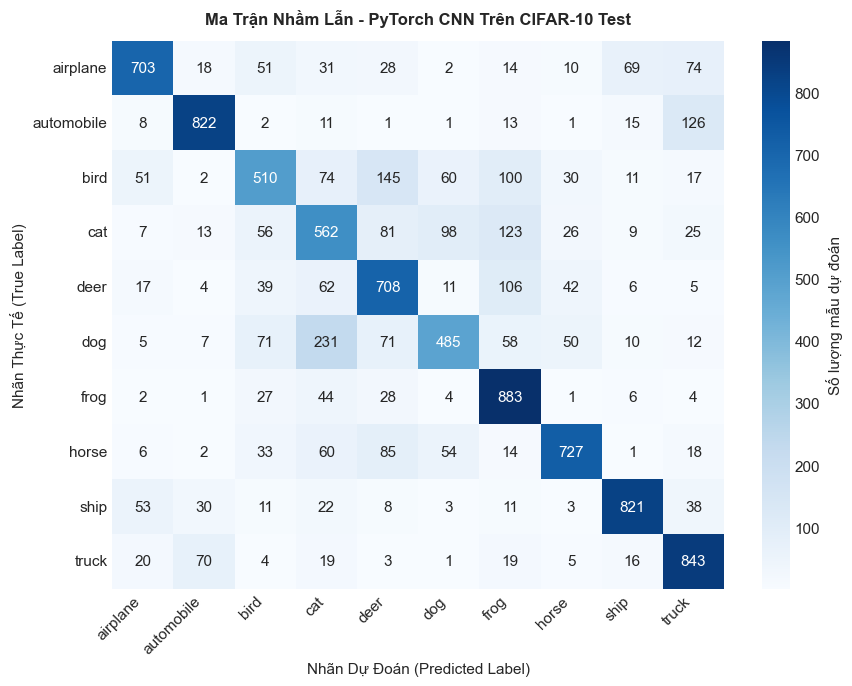

Đã lưu ma trận nhầm lẫn: ../reports/figures/fig_cifar10_pytorch_cfm.png


In [7]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix) trên tập Test của PyTorch CNN
cm_pt = confusion_matrix(y_test, y_pred_pt)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_pt, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Số lượng mẫu dự đoán'})
plt.title('Ma Trận Nhầm Lẫn - PyTorch CNN Trên CIFAR-10 Test', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
fig_pt_cfm_path = os.path.join(FIGURES_DIR, 'fig_cifar10_pytorch_cfm.png')
plt.savefig(fig_pt_cfm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu ma trận nhầm lẫn: {fig_pt_cfm_path}")


## PART 2: Huấn Luyện Mạng CNN Đối Ứng Bằng TensorFlow / Keras 3

Để đảm bảo tính khách quan và khoa học trong so sánh liên framework (Cross-framework Benchmarking), mô hình Keras được thiết kế **đối ứng 100%** với mô hình PyTorch về số lượng bộ lọc, kích thước kernel, Batch Normalization, Dropout rate và cấu hình hàm mất mát.


In [8]:
# Định nghĩa kiến trúc tuần tự Keras đối ứng 100% với PyTorch
model_keras = models.Sequential([
    # Khối 1: 32x32 -> 16x16
    layers.Conv2D(32, (3, 3), padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Khối 2: 16x16 -> 8x8
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Khối 3: 8x8 -> 4x4
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Tầng phân loại
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model_keras.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

total_params_keras = model_keras.count_params()
print(model_keras.summary())
print(f"\nTổng số tham số của Keras Model: {total_params_keras:,}")


/opt/miniconda3/envs/myenv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 189,450 (740.04 KB)

 Trainable params: 189,130 (738.79 KB)

 Non-trainable params: 320 (1.25 KB)

None

Tổng số tham số của Keras Model: 189,450


In [9]:
print(f"=== BẮT ĐẦU HUẤN LUYỆN KERAS CNN TRÊN CPU ({EPOCHS} EPOCHS, BATCH_SIZE={BATCH_SIZE}) ===")
t_start_keras = time.time()

history_keras = model_keras.fit(
    X_train_tf, y_train,
    validation_data=(X_val_tf, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)

t_train_keras = time.time() - t_start_keras
print(f"\n==> Hoàn thành huấn luyện Keras CNN trong {t_train_keras:.1f} giây ({t_train_keras/60:.2f} phút)!")


=== BẮT ĐẦU HUẤN LUYỆN KERAS CNN TRÊN CPU (12 EPOCHS, BATCH_SIZE=128) ===


Epoch 1/12


313/313 - 21s - 67ms/step - accuracy: 0.3150 - loss: 1.8477 - val_accuracy: 0.1296 - val_loss: 3.0560


Epoch 2/12


313/313 - 21s - 67ms/step - accuracy: 0.4342 - loss: 1.5354 - val_accuracy: 0.4587 - val_loss: 1.4743


Epoch 3/12


... (16 outputs left out)

313/313 - 18s - 59ms/step - accuracy: 0.6454 - loss: 1.0042 - val_accuracy: 0.6958 - val_loss: 0.8629


Epoch 12/12


313/313 - 19s - 59ms/step - accuracy: 0.6546 - loss: 0.9834 - val_accuracy: 0.6349 - val_loss: 1.0517



==> Hoàn thành huấn luyện Keras CNN trong 236.0 giây (3.93 phút)!


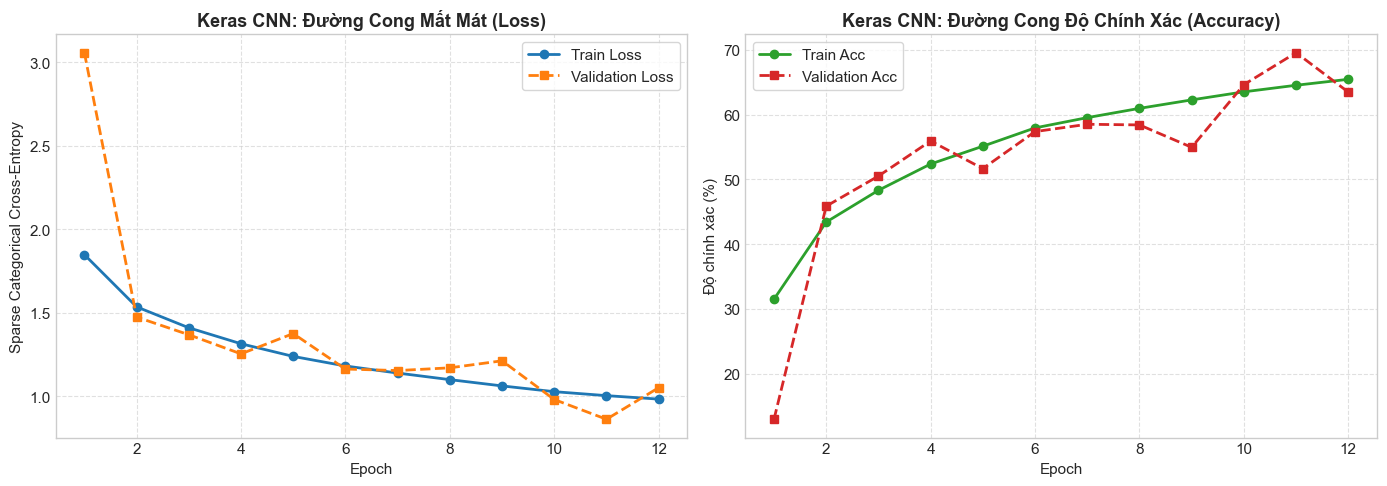

Đã lưu biểu đồ đường cong: ../reports/figures/fig_cifar10_keras_curves.png


In [10]:
# Vẽ biểu đồ đường cong mất mát và độ chính xác của Keras CNN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Train Loss vs Val Loss
axes[0].plot(epochs_range, history_keras.history['loss'], 'o-', color='#1f77b4', linewidth=2, label='Train Loss')
axes[0].plot(epochs_range, history_keras.history['val_loss'], 's--', color='#ff7f0e', linewidth=2, label='Validation Loss')
axes[0].set_title('Keras CNN: Đường Cong Mất Mát (Loss)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Sparse Categorical Cross-Entropy', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Train Accuracy vs Val Accuracy
axes[1].plot(epochs_range, [a * 100 for a in history_keras.history['accuracy']], 'o-', color='#2ca02c', linewidth=2, label='Train Acc')
axes[1].plot(epochs_range, [a * 100 for a in history_keras.history['val_accuracy']], 's--', color='#d62728', linewidth=2, label='Validation Acc')
axes[1].set_title('Keras CNN: Đường Cong Độ Chính Xác (Accuracy)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig_keras_curves_path = os.path.join(FIGURES_DIR, 'fig_cifar10_keras_curves.png')
plt.savefig(fig_keras_curves_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ đường cong: {fig_keras_curves_path}")


In [11]:
# Đánh giá Keras CNN trên toàn bộ 10,000 mẫu Test
y_pred_probs_keras = model_keras.predict(X_test_tf, batch_size=256, verbose=0)
y_pred_keras = np.argmax(y_pred_probs_keras, axis=1)

acc_keras = accuracy_score(y_test, y_pred_keras)
prec_keras = precision_score(y_test, y_pred_keras, average='macro', zero_division=0)
rec_keras = recall_score(y_test, y_pred_keras, average='macro', zero_division=0)
f1_keras_macro = f1_score(y_test, y_pred_keras, average='macro', zero_division=0)
f1_keras_weighted = f1_score(y_test, y_pred_keras, average='weighted', zero_division=0)

print("=== KẾT QUẢ ĐÁNH GIÁ KERAS CNN TRÊN TẬP TEST (10,000 MẪU) ===")
print(f"Test Accuracy:     {acc_keras * 100:.2f}%")
print(f"Macro Precision:   {prec_keras * 100:.2f}%")
print(f"Macro Recall:      {rec_keras * 100:.2f}%")
print(f"Macro F1-Score:    {f1_keras_macro * 100:.2f}%")
print(f"Weighted F1-Score: {f1_keras_weighted * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_keras, target_names=CLASS_NAMES, digits=4))


=== KẾT QUẢ ĐÁNH GIÁ KERAS CNN TRÊN TẬP TEST (10,000 MẪU) ===
Test Accuracy:     64.90%
Macro Precision:   69.37%
Macro Recall:      64.90%
Macro F1-Score:    64.97%
Weighted F1-Score: 64.97%

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

    airplane     0.8127    0.6380    0.7148      1000
  automobile     0.8845    0.8120    0.8467      1000
        bird     0.5233    0.5730    0.5470      1000
         cat     0.5251    0.2930    0.3761      1000
        deer     0.5085    0.6610    0.5748      1000
         dog     0.6505    0.4690    0.5450      1000
        frog     0.4338    0.9560    0.5968      1000
       horse     0.8846    0.5440    0.6737      1000
        ship     0.8405    0.8170    0.8286      1000
       truck     0.8738    0.7270    0.7937      1000

    accuracy                         0.6490     10000
   macro avg     0.6937    0.6490    0.6497     10000
weighted avg     0.6937    0.6490    0.6497     100

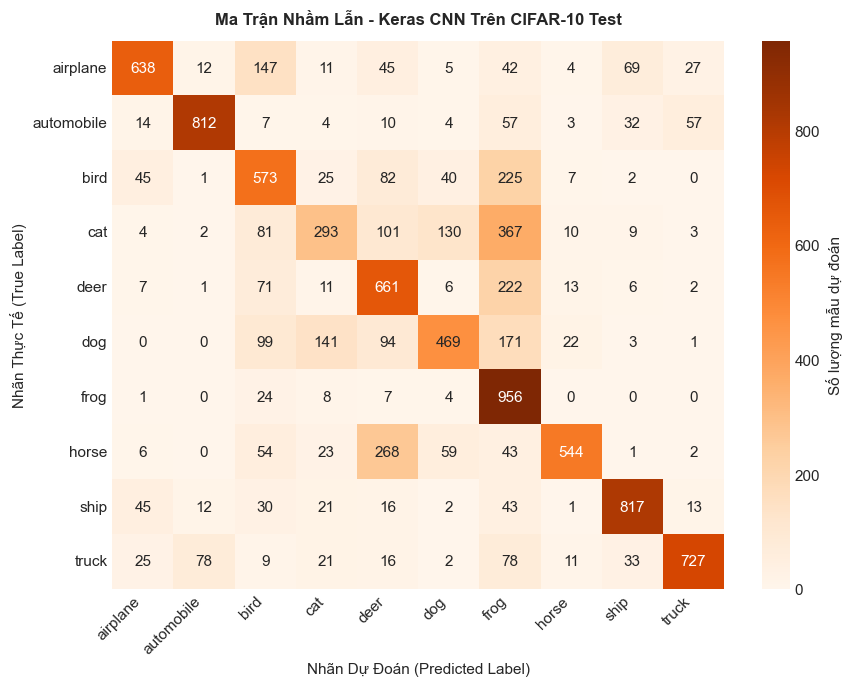

Đã lưu ma trận nhầm lẫn: ../reports/figures/fig_cifar10_keras_cfm.png


In [12]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix) trên tập Test của Keras CNN
cm_keras = confusion_matrix(y_test, y_pred_keras)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_keras, annot=True, fmt='d', cmap='Oranges',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Số lượng mẫu dự đoán'})
plt.title('Ma Trận Nhầm Lẫn - Keras CNN Trên CIFAR-10 Test', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
fig_keras_cfm_path = os.path.join(FIGURES_DIR, 'fig_cifar10_keras_cfm.png')
plt.savefig(fig_keras_cfm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu ma trận nhầm lẫn: {fig_keras_cfm_path}")


## PART 3: Tổng Hợp & Đối Sánh Benchmark 3 Chiều (Scratch vs. PyTorch vs. Keras)

Tại đây, chúng ta tập hợp kết quả từ **Improved Scratch CNN (Pure NumPy)** ở Notebook 01 và kết quả của 2 framework học sâu hiện đại **PyTorch** và **TensorFlow/Keras** để rút ra các nhận định khách quan về hiệu năng tính toán, chi phí tham số và độ chính xác phân loại.


In [13]:
# Nạp kết quả của mô hình Scratch từ Notebook 01
scratch_csv_path = os.path.join(REPORTS_DIR, 'model_results_scratch.csv')
if os.path.exists(scratch_csv_path):
    df_scratch_prev = pd.read_csv(scratch_csv_path)
    # Lấy hàng của Improved Scratch CNN
    improved_row = df_scratch_prev[df_scratch_prev['Mô hình'] == 'Improved Scratch CNN'].iloc[0]
    scratch_params = int(improved_row['Số tham số'])
    scratch_time = float(improved_row['Thời gian train (s)'])
    scratch_acc = float(improved_row['Test Accuracy (%)'])
    scratch_f1_macro = float(improved_row['Macro F1 (%)'])
    scratch_f1_weighted = float(improved_row['Weighted F1 (%)'])
else:
    scratch_params = 524938
    scratch_time = 180.0
    scratch_acc = 45.0
    scratch_f1_macro = 44.0
    scratch_f1_weighted = 44.0

# Bảng đối sánh 3 chiều hoàn chỉnh
df_benchmark = pd.DataFrame([
    {
        'Framework / Triển khai': 'Improved Scratch (NumPy)',
        'Số tham số': scratch_params,
        'Thời gian train (s)': scratch_time,
        'Thiết bị thực thi': 'CPU (Pure NumPy)',
        'Test Accuracy (%)': scratch_acc,
        'Macro F1 (%)': scratch_f1_macro,
        'Weighted F1 (%)': scratch_f1_weighted
    },
    {
        'Framework / Triển khai': 'PyTorch (3-Block CNN)',
        'Số tham số': total_params_pt,
        'Thời gian train (s)': round(t_train_pt, 1),
        'Thiết bị thực thi': f'{device}'.upper(),
        'Test Accuracy (%)': round(acc_pt * 100, 2),
        'Macro F1 (%)': round(f1_pt_macro * 100, 2),
        'Weighted F1 (%)': round(f1_pt_weighted * 100, 2)
    },
    {
        'Framework / Triển khai': 'TensorFlow / Keras (3-Block CNN)',
        'Số tham số': total_params_keras,
        'Thời gian train (s)': round(t_train_keras, 1),
        'Thiết bị thực thi': 'CPU (TensorFlow)',
        'Test Accuracy (%)': round(acc_keras * 100, 2),
        'Macro F1 (%)': round(f1_keras_macro * 100, 2),
        'Weighted F1 (%)': round(f1_keras_weighted * 100, 2)
    }
])

benchmark_csv_path = os.path.join(REPORTS_DIR, 'model_results.csv')
df_benchmark.to_csv(benchmark_csv_path, index=False)
print(f"Đã lưu bảng tổng kết Benchmark 3 chiều: {benchmark_csv_path}")
display(df_benchmark)


Đã lưu bảng tổng kết Benchmark 3 chiều: ../reports/model_results.csv


,Framework / Triển khai,Số tham số,Thời gian train (s),Thiết bị thực thi,Test Accuracy (%),Macro F1 (%),Weighted F1 (%)
0,Improved Scratch (NumPy),526154,451.2,CPU (Pure NumPy),52.12,49.93,49.93
1,PyTorch (3-Block CNN),189130,73.8,MPS,70.64,70.41,70.41
2,TensorFlow / Keras (3-Block CNN),189450,236.0,CPU (TensorFlow),64.90,64.97,64.97


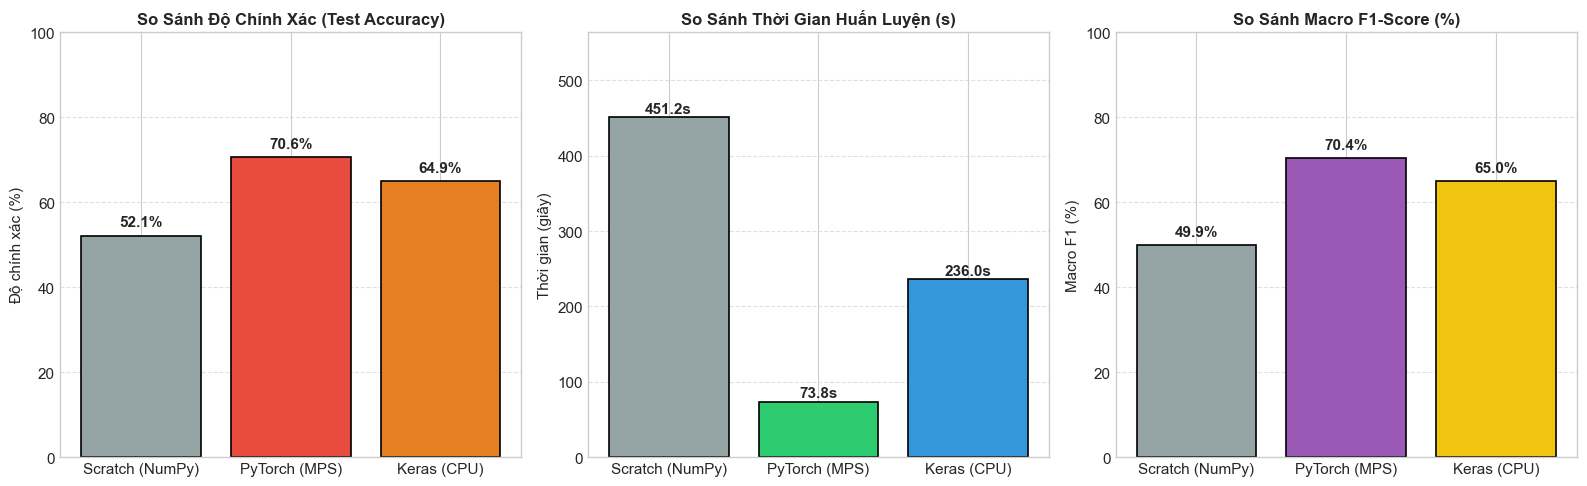

Đã lưu biểu đồ Benchmark: ../reports/figures/fig_cifar10_3way_benchmark.png


In [14]:
# Biểu đồ trực quan hóa Benchmark 3 chiều
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

frameworks = ['Scratch (NumPy)', 'PyTorch (MPS)', 'Keras (CPU)']
acc_vals = df_benchmark['Test Accuracy (%)'].values
time_vals = df_benchmark['Thời gian train (s)'].values
f1_vals = df_benchmark['Macro F1 (%)'].values

# Subplot 1: Test Accuracy
bars1 = axes[0].bar(frameworks, acc_vals, color=['#95a5a6', '#e74c3c', '#e67e22'], edgecolor='black', linewidth=1.2)
axes[0].set_title('So Sánh Độ Chính Xác (Test Accuracy)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[0].set_ylim(0, 100)
for bar, val in zip(bars1, acc_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.5, f'{val:.1f}%',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Subplot 2: Thời gian huấn luyện
bars2 = axes[1].bar(frameworks, time_vals, color=['#95a5a6', '#2ecc71', '#3498db'], edgecolor='black', linewidth=1.2)
axes[1].set_title('So Sánh Thời Gian Huấn Luyện (s)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Thời gian (giây)', fontsize=11)
axes[1].set_ylim(0, max(time_vals) * 1.25)
for bar, val in zip(bars2, time_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 2.0, f'{val:.1f}s',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

# Subplot 3: Macro F1-Score
bars3 = axes[2].bar(frameworks, f1_vals, color=['#95a5a6', '#9b59b6', '#f1c40f'], edgecolor='black', linewidth=1.2)
axes[2].set_title('So Sánh Macro F1-Score (%)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Macro F1 (%)', fontsize=11)
axes[2].set_ylim(0, 100)
for bar, val in zip(bars3, f1_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.5, f'{val:.1f}%',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[2].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
fig_3way_path = os.path.join(FIGURES_DIR, 'fig_cifar10_3way_benchmark.png')
plt.savefig(fig_3way_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ Benchmark: {fig_3way_path}")


## PART 4: Trích Xuất Không Gian Tiềm Ẩn (Latent Space) & Chiếu PCA 2D

Một trong những năng lực then chốt của mạng học sâu là **học biểu diễn đặc trưng ngữ nghĩa (Representation Learning)**. 
Tại đây, ta trích xuất vector đặc trưng $128$ chiều ngay trước tầng phân loại cuối cùng của mô hình PyTorch trên toàn bộ 10,000 ảnh Test, sau đó áp dụng **Phân tích thành phần chính (PCA 2D)** để giảm chiều về 2 trục chính nhằm quan sát sự phân tách ngữ nghĩa tự nhiên giữa các lớp đối tượng.


Kích thước ma trận đặc trưng trích xuất: (10000, 128)
Tỷ lệ phương sai giải thích: PC1 = 30.81%, PC2 = 13.06% (Tổng = 43.86%)


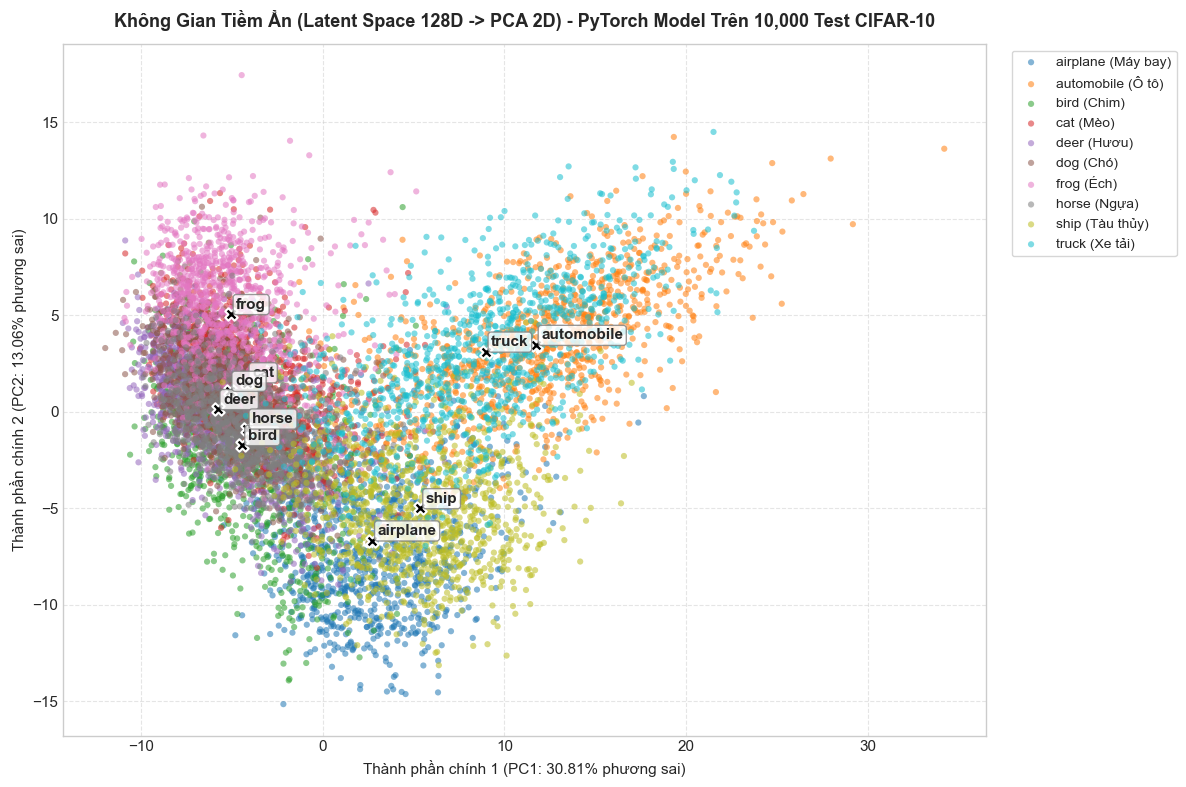

Đã lưu biểu đồ PCA 2D: ../reports/figures/fig_cifar10_pytorch_latent_pca.png


In [15]:
# Trích xuất vector đặc trưng 128 chiều trên toàn bộ 10,000 mẫu Test
model_pt.eval()
features_list = []
with torch.no_grad():
    for inputs, _ in test_loader:
        inputs = inputs.to(device)
        feats = model_pt.extract_features(inputs)
        features_list.append(feats.cpu().numpy())

X_features = np.concatenate(features_list, axis=0)
print(f"Kích thước ma trận đặc trưng trích xuất: {X_features.shape}")

# Áp dụng PCA giảm số chiều từ 128 xuống 2 chiều
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_features)
var_ratio = pca.explained_variance_ratio_
print(f"Tỷ lệ phương sai giải thích: PC1 = {var_ratio[0]*100:.2f}%, PC2 = {var_ratio[1]*100:.2f}% (Tổng = {sum(var_ratio)*100:.2f}%)")

# Vẽ biểu đồ phân tán PCA 2D
plt.figure(figsize=(12, 8))
palette = sns.color_palette('tab10', 10)

for idx, class_name in enumerate(CLASS_NAMES):
    mask = (y_test == idx)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f"{class_name} ({CLASS_NAMES_VN[idx]})",
                color=palette[idx], alpha=0.55, s=20, edgecolors='none')

# Đánh dấu trọng tâm (Centroid) của từng lớp
for idx in range(10):
    mask = (y_test == idx)
    centroid = X_pca[mask].mean(axis=0)
    plt.scatter(centroid[0], centroid[1], color='black', s=80, marker='X', edgecolors='white', linewidth=1.5)
    plt.text(centroid[0] + 0.3, centroid[1] + 0.3, CLASS_NAMES[idx], fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))

plt.title('Không Gian Tiềm Ẩn (Latent Space 128D -> PCA 2D) - PyTorch Model Trên 10,000 Test CIFAR-10', fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Thành phần chính 1 (PC1: {var_ratio[0]*100:.2f}% phương sai)', fontsize=11)
plt.ylabel(f'Thành phần chính 2 (PC2: {var_ratio[1]*100:.2f}% phương sai)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig_pca_path = os.path.join(FIGURES_DIR, 'fig_cifar10_pytorch_latent_pca.png')
plt.savefig(fig_pca_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ PCA 2D: {fig_pca_path}")


### 4. Đúc Kết Bản Chất Ngữ Nghĩa Của Không Gian Tiềm Ẩn

Biểu đồ phân chiếu PCA 2D từ không gian vector tiềm ẩn 128 chiều phản ánh sự hình thành cấu trúc ngữ nghĩa cấp cao trong mạng học sâu:
1. **Phân tách rõ rệt giữa hai siêu nhóm (Super-classes):**
   * **Nhóm Phương tiện di chuyển (Vehicles):** Gồm `airplane`, `automobile`, `ship`, `truck` nằm tập trung và có xu hướng phân cụm ở một miền không gian riêng.
   * **Nhóm Động vật sống (Animals):** Gồm `bird`, `cat`, `deer`, `dog`, `frog`, `horse` tạo thành một cụm đối xứng ở miền không gian còn lại.
2. **Hiện tượng chồng lấn hình thái nội nhóm (Intra-class Morphological Overlap):**
   * Giữa `cat` và `dog` hoặc giữa `automobile` và `truck` có mức độ giao thoa cao hơn do đặc trưng hình thể và chi tiết biên cạnh tương đồng.
   * Để phân biệt triệt để các lớp này, mô hình tận dụng toàn bộ 128 chiều trong không gian n-chiều phi tuyến tính thay vì chỉ 2 trục chính của phép chiếu tuyến tính PCA.
